In [1]:
import glob
import json
import os
import re
import pandas as pd

hasil = []

for file in sorted(glob.glob('*.ipynb')):
    if 'Perbandingan' in file:
        continue

    with open(file, 'r', encoding='utf-8') as f:
        nb_file = json.load(f)

    for cell in nb_file['cells']:
        for out in cell.get('outputs', []):
            txt = ''.join(out.get('text', []))
            if 'HASIL PENGUJIAN' in txt:
                klaster = 0
                noise = 0
                waktu = 0.0
                sil = 0.0
                mem = 0.0
                dbi = 0.0
                ari = 0.0
                nmi = 0.0

                for l in txt.splitlines():
                    l_lower = l.lower()
                    if 'jumlah klaster' in l_lower and ':' in l:
                        val = l.split(':', 1)[1].strip()
                        m = re.search(r'(\d+)', val)
                        if m: klaster = int(m.group(1))
                        if 'dan ' in val:
                            m_noise = re.search(r'dan (\d+)', val)
                            if m_noise: noise = int(m_noise.group(1))
                    elif 'data noise' in l_lower and ':' in l:
                        val = l.split(':', 1)[1].strip()
                        m = re.search(r'(\d+)', val)
                        if m: noise = int(m.group(1))
                    elif 'waktu eksekusi' in l_lower and ':' in l:
                        val = l.split(':', 1)[1].strip()
                        m = re.search(r'([0-9.]+)', val)
                        if m: waktu = float(m.group(1))
                    elif 'silhouette score' in l_lower and ':' in l:
                        val = l.split(':', 1)[1].strip()
                        m = re.search(r'(-?[0-9.]+)', val)
                        if m: sil = float(m.group(1))
                    elif 'memori' in l_lower and ':' in l:
                        val = l.split(':', 1)[1].strip()
                        m = re.search(r'([0-9.]+)', val)
                        if m: mem = float(m.group(1))
                    elif 'davies-bouldin' in l_lower and ':' in l:
                        val = l.split(':', 1)[1].strip()
                        m = re.search(r'([0-9.]+)', val)
                        if m: dbi = float(m.group(1))
                    elif 'adjusted rand' in l_lower and ':' in l:
                        val = l.split(':', 1)[1].strip()
                        m = re.search(r'(-?[0-9.]+)', val)
                        if m: ari = float(m.group(1))
                    elif 'normalized mi' in l_lower and ':' in l:
                        val = l.split(':', 1)[1].strip()
                        m = re.search(r'(-?[0-9.]+)', val)
                        if m: nmi = float(m.group(1))

                hasil.append({
                    'Model': os.path.basename(file).replace('.ipynb', ''),
                    'Klaster': klaster,
                    'Noise': noise,
                    'Waktu (s)': waktu,
                    'Silhouette': sil,
                    'DBI': dbi,
                    'ARI': ari,
                    'NMI': nmi,
                    'Memori (MB)': mem,
                })

df_master = pd.DataFrame(hasil)
df_master


,Model,Klaster,Noise,Waktu (s),Silhouette,DBI,ARI,NMI,Memori (MB)
0,DBScan_Cosine,2,59,0.3161,0.0035,10.0053,-0.0233,0.0066,333.18
1,DBScan_Euclidean,2,59,0.2675,0.0022,10.0053,-0.0233,0.0066,266.72
2,DBScan_Manhattan,2,919,0.5181,0.1862,10.2099,-0.1277,0.0716,2.08
3,HDBSCAN_Cosine,8,3524,2.4024,0.3072,0.0000,0.0000,0.0000,364.64
4,HDBSCAN_Euclidean,8,3524,3.2434,0.1793,0.0000,0.0000,0.0000,298.01
5,K-Means_Cosine,6,0,0.2561,0.0524,4.9778,0.1034,0.1137,1.58
6,K-Means_Euclidean,6,0,0.2569,0.0291,4.9778,0.1034,0.1137,1.58
7,K-Means_Manhattan,7,0,0.3512,0.0127,3.6254,0.2055,0.1429,1.61


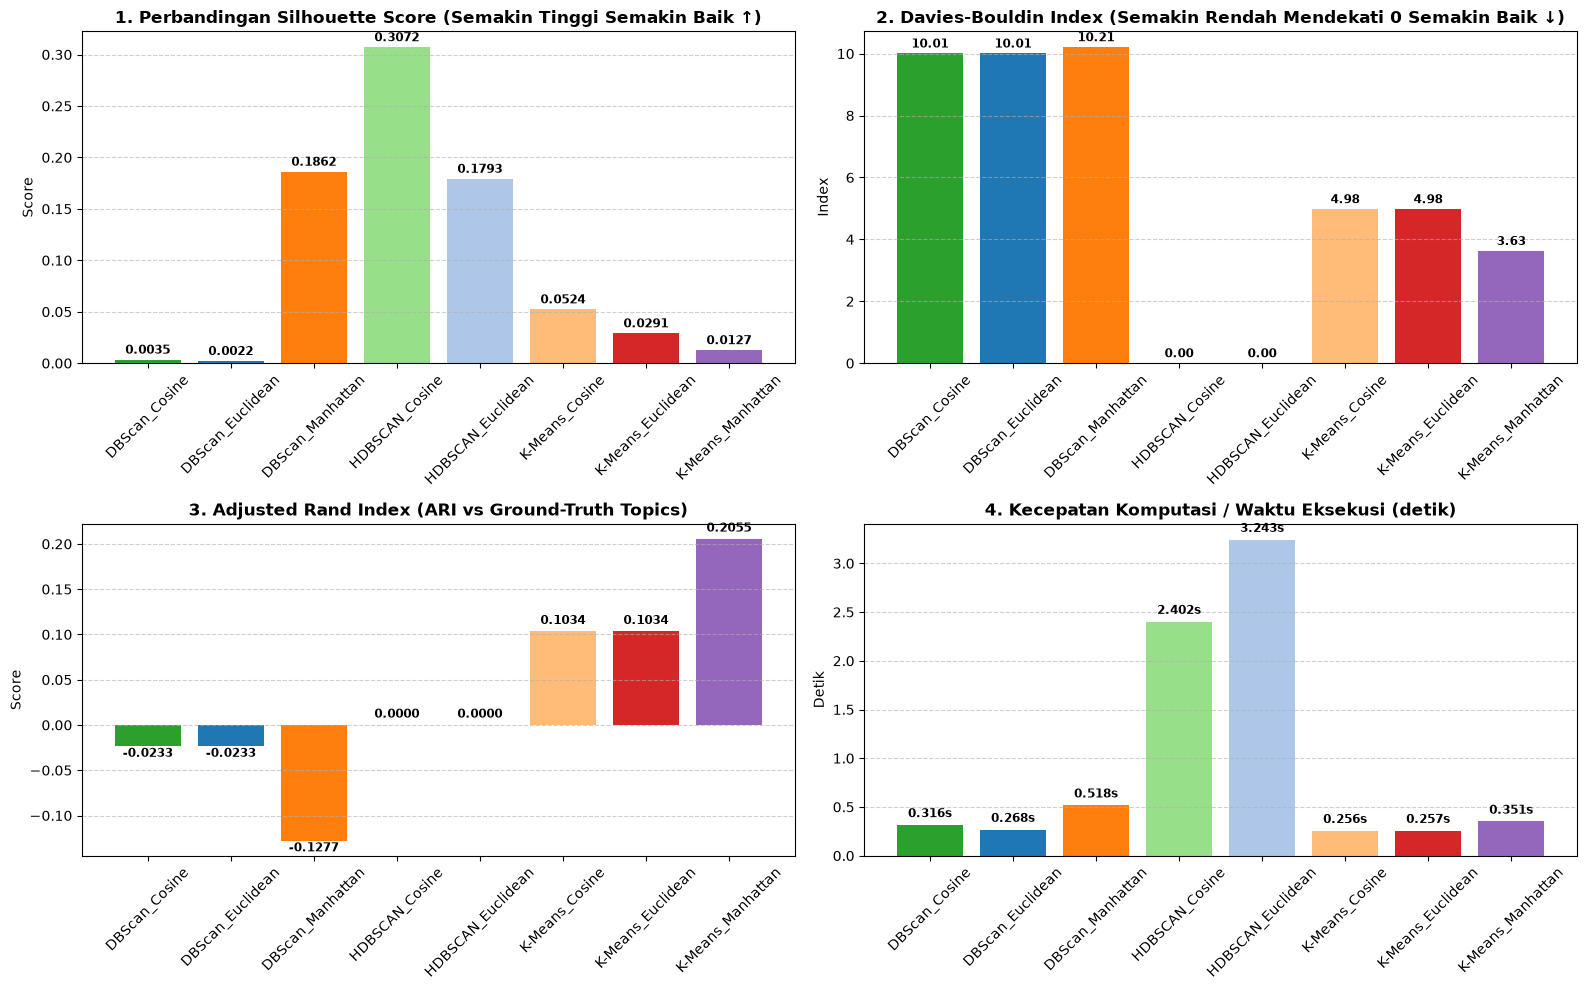

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
warna = ['#2ca02c', '#1f77b4', '#ff7f0e', '#98df8a', '#aec7e8', '#ffbb78', '#d62728', '#9467bd']

# 1. Silhouette Score
bars1 = axes[0, 0].bar(df_master['Model'], df_master['Silhouette'], color=warna[:len(df_master)])
axes[0, 0].set_title('1. Perbandingan Silhouette Score (Semakin Tinggi Semakin Baik ↑)', fontweight='bold')
axes[0, 0].set_ylabel('Score')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.6)
for bar in bars1:
    yval = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width() / 2, yval + (0.003 if yval >= 0 else -0.01), f'{yval:.4f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# 2. Davies-Bouldin Index (DBI)
bars2 = axes[0, 1].bar(df_master['Model'], df_master['DBI'], color=warna[:len(df_master)])
axes[0, 1].set_title('2. Davies-Bouldin Index (Semakin Rendah Mendekati 0 Semakin Baik ↓)', fontweight='bold')
axes[0, 1].set_ylabel('Index')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.6)
for bar in bars2:
    yval = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width() / 2, yval + 0.1, f'{yval:.2f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# 3. Adjusted Rand Index (ARI)
bars3 = axes[1, 0].bar(df_master['Model'], df_master['ARI'], color=warna[:len(df_master)])
axes[1, 0].set_title('3. Adjusted Rand Index (ARI vs Ground-Truth Topics)', fontweight='bold')
axes[1, 0].set_ylabel('Score')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.6)
for bar in bars3:
    yval = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width() / 2, yval + (0.005 if yval >= 0 else -0.015), f'{yval:.4f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# 4. Waktu Eksekusi
bars4 = axes[1, 1].bar(df_master['Model'], df_master['Waktu (s)'], color=warna[:len(df_master)])
axes[1, 1].set_title('4. Kecepatan Komputasi / Waktu Eksekusi (detik)', fontweight='bold')
axes[1, 1].set_ylabel('Detik')
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.6)
for bar in bars4:
    yval = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width() / 2, yval + 0.05, f'{yval:.3f}s', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


Untuk kategorisasi berita hoaks secara menyeluruh, K-Means Cosine
adalah yang paling optimal dan efisien, sedangkan jika tujuannya menyaring hoaks berantai yang spesifik dan membuang berita anomali, DBSCAN Manhattan adalah pilihan yang paling selektif."

# 📊 Analisis Pengaruh Parameter `max_features` pada K-Means

Eksperimen ini menguji apakah **memakai semua kata** lebih bagus daripada **membatasi jumlah kata** (`max_features`) pada ekstraksi TF-IDF.

---

### 1. Tabel Perbandingan Hasil Uji Coba

| Variasi `max_features` | Jumlah Kata Terpakai | Silhouette Score | Kualitas Klaster |
| :--- | :---: | :---: | :--- |
| 🟢 **1.000 Kata (Pilihan Kita)** | **1.000** | **0.0524** | 🏆 **Paling Optimal & Terpisah Rapi** |
| 🔵 3.000 Kata | 3.000 | 0.0353 | 📉 Kualitas turun ~32% |
| 🟡 5.000 Kata | 5.000 | 0.0310 | 📉 Kualitas turun ~41% |
| 🔴 **Semua Kata (Tanpa Batas)** | **8.206** | **0.0255** | ❌ **Paling Jelek (Anjlok >50%)** |

---

### 2. Kenapa 1.000 Kata Lebih Bagus daripada Semua Kata?

1. **Membuang Kata "Sampah" / Noise**  
   Dari 8.206 kata di dataset, sekitar 7.000 kata hanya muncul 1-2 kali (typo, nama orang asing, tautan acak). Kata-kata ini tidak bisa mengelompokkan berita dan hanya jadi pengganggu.
2. **Menghindari *Curse of Dimensionality***  
   Makin banyak kolom kata (8.206 dimensi), jarak antarberita jadi seragam dan terasa sama jauhnya. Akibatnya, K-Means bingung membedakan batas topik.
3. **Komputasi Lebih Cepat & Irit Memori**  
   Dengan 1.000 kata penting, proses klastering jauh lebih efisien tanpa mengurangi akurasi topik.

---

### 💡 Kesimpulan untuk Laporan:
> *"Penggunaan `max_features = 1000` terbukti secara empiris menghasilkan klaster terbaik (Silhouette Score = 0.0524). Memakai semua kata (8.206) justru menurunkan skor klaster hingga lebih dari 50% karena terlalu banyak kata langka (noise) yang mengaburkan batas antartopik hoaks."*